# Quickstart: JAX & Hamiltonian mechanics

A hands-on tour of `hamjax`. Run the cells top to bottom, then change things and re-run.

**Setup** (once, from the repo root):

```bash
pip install -e ".[dev]"
pip install jupyter
jupyter notebook notebooks/quickstart.ipynb
```

## 1. Imports

Double precision makes long-time energy conservation measurable, so turn it on before anything else.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt

import hamjax as hj

# Colours used in the plots below.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

## 2. The figure-eight three-body orbit

`figure_eight()` returns the starting positions and momenta, the masses, and the orbit's period.
`NBody` only defines the **energy**. Forces come from `jax.grad`.

In [2]:
state, masses, period = hj.figure_eight()
H = hj.NBody(masses, G=1.0, softening=0.0)

print("positions q:\n", state.q)
print("momenta p:\n", state.p)
print("period:", period)
print("total energy H:", H(state))

positions q:
 [[ 0.97000436 -0.24308753]
 [-0.97000436  0.24308753]
 [ 0.          0.        ]]
momenta p:
 [[ 0.46620368  0.43236573]
 [ 0.46620368  0.43236573]
 [-0.93240737 -0.86473146]]
period: 6.32591398


total energy H: -1.2871419917663254


Forces are computed by autodiff: `force(q) = -jax.grad(H.potential)(q)`. They add up to zero (Newton's third law).

In [3]:
F = H.force(state.q)
print("forces:\n", F)
print("sum of forces:", F.sum(axis=0))

forces:
 [[-1.21250544  0.30385941]
 [ 1.21250544 -0.30385941]
 [-0.         -0.        ]]
sum of forces: [0. 0.]


## 3. Simulate

`simulate` runs velocity Verlet inside a single `lax.scan`.
Here: 100 periods at 1,000 steps per period, keeping every 10th state (100 points per orbit).

In [4]:
traj = hj.simulate(H, state, dt=period / 1000, n_steps=100_000, save_every=10)

traj.q.shape  # (saved times, bodies, x/y)

(10001, 3, 2)

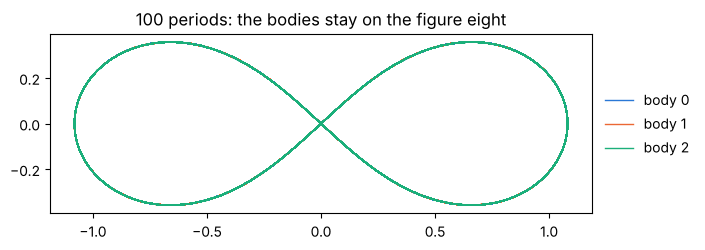

In [5]:
plt.figure(figsize=(7, 3))
for i, c in enumerate([BLUE, ORANGE, AQUA]):
    plt.plot(traj.q[:, i, 0], traj.q[:, i, 1], color=c, lw=1, label=f"body {i}")
plt.gca().set_aspect("equal")
plt.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("100 periods: the bodies stay on the figure eight")
plt.show()

## 4. Energy conservation

The relative energy error stays small and bounded. It wobbles but doesn't drift, which is the signature of a symplectic integrator.

max relative energy error: 2.3597768344076488e-05


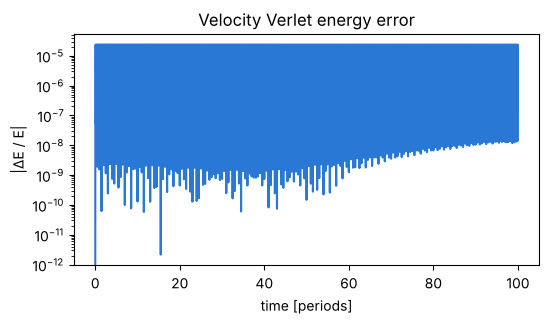

In [6]:
err = hj.relative_energy_error(H, traj)
print("max relative energy error:", err.max())

plt.figure(figsize=(6, 3))
plt.semilogy(traj.t / period, err, color=BLUE)
plt.xlabel("time [periods]")
plt.ylabel("|ΔE / E|")
plt.title("Velocity Verlet energy error")
plt.show()

## 5. Compare integrators

Same step size, three methods, run for 1,000 periods at a coarse 100 steps per period.
RK4 starts out more accurate but **drifts**; the symplectic methods stay bounded.

Velocity Verlet  final energy error: 2.1e-03


RK4              final energy error: 3.1e-02


Yoshida 4        final energy error: 5.4e-06


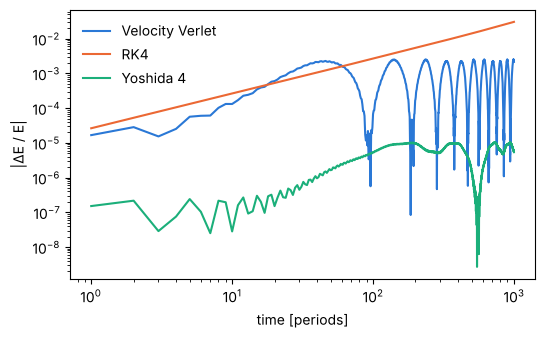

In [7]:
plt.figure(figsize=(6, 3.5))
for name, integ, c in [
    ("Velocity Verlet", hj.VelocityVerlet(), BLUE),
    ("RK4", hj.RK4(), ORANGE),
    ("Yoshida 4", hj.Yoshida4(), AQUA),
]:
    tr = hj.simulate(H, state, dt=period / 100, n_steps=100_000, integrator=integ, save_every=100)
    e = hj.relative_energy_error(H, tr)
    plt.loglog(tr.t[1:] / period, e[1:], color=c, label=name)
    print(f"{name:16s} final energy error: {float(e[-1]):.1e}")
plt.xlabel("time [periods]")
plt.ylabel("|ΔE / E|")
plt.legend(frameon=False)
plt.show()

## 6. Your own system: just write the energy

Subclass `SeparableHamiltonian` and implement `kinetic(p)` and `potential(q)`.
Here: a chain of 8 particles joined by springs with an extra quartic (anharmonic) term.

In [8]:
class AnharmonicChain(hj.SeparableHamiltonian):
    k: float = 1.0

    def kinetic(self, p):
        return 0.5 * jnp.sum(p**2)

    def potential(self, q):
        return jnp.sum(0.5 * self.k * jnp.diff(q) ** 2 + 0.25 * jnp.diff(q) ** 4)


chain = AnharmonicChain()
q0, p0 = jnp.linspace(0, 1, 8) ** 2, jnp.zeros(8)
traj2 = hj.simulate(chain, hj.PhaseSpace(q0, p0), dt=0.01, n_steps=10_000)

print("trajectory shape:", traj2.q.shape)
print("max relative energy error:", hj.relative_energy_error(chain, traj2).max())

trajectory shape: (10001, 8)
max relative energy error: 1.0036619279062826e-05


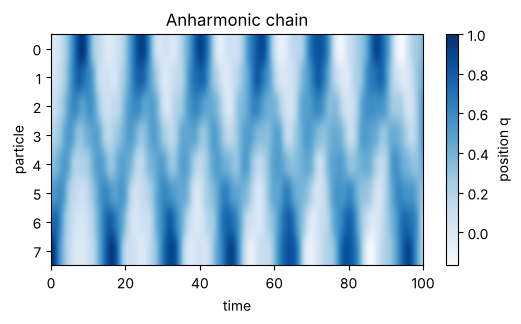

In [9]:
plt.figure(figsize=(6, 3))
plt.imshow(traj2.q.T, aspect="auto", cmap="Blues", extent=[0, float(traj2.t[-1]), 7.5, -0.5])
plt.colorbar(label="position q")
plt.xlabel("time")
plt.ylabel("particle")
plt.title("Anharmonic chain")
plt.show()

## 7. Things to try

- Change `dt` in section 3 (e.g. `period / 50`) and watch the energy error grow by about 4×. Verlet is second order.
- Replace `hj.figure_eight()` with `hj.kepler_two_body(eccentricity=0.9)`.
- Nudge one momentum (`state.p.at[0, 0].add(0.01)`) and watch the choreography break up.
- Set `k=5.0` in `AnharmonicChain(k=5.0)`, or make the chain longer.
- Differentiate *through* a simulation: `jax.grad(lambda p0: hj.simulate(H, hj.PhaseSpace(state.q, p0), dt=0.01, n_steps=100).q[-1].sum())(state.p)`.

For more, see the scripts in `examples/`.